In [1]:
   %load_ext autoreload
   %autoreload 2

S10_E1_A1 done
S10_E1_A2 done
S10_E1_A3 done
S11_E1_A1 done
S11_E1_A2 done
S11_E1_A3 done
S12_E1_A1 done
S12_E1_A2 done
S12_E1_A3 done
S1_E1_A1 done
S1_E1_A2 done
S1_E1_A3 done
S2_E1_A1 done
S2_E1_A2 done
S2_E1_A3 done
S3_E1_A1 done
S3_E1_A2 done
S3_E1_A3 done
S4_E1_A1 done
S4_E1_A2 done
S4_E1_A3 done
S5_E1_A1 done
S5_E1_A2 done
S5_E1_A3 done
S6_E1_A1 done
S6_E1_A2 done
S6_E1_A3 done
S7_E1_A1 done
S7_E1_A2 done
S7_E1_A3 done
S8_E1_A1 done
S8_E1_A2 done
S8_E1_A3 done
S9_E1_A1 done
S9_E1_A2 done
S9_E1_A3 done
           n  median    q25    q75  emg_first_pct
subject                                          
1        181   -25.0 -175.0   55.0             43
2        193    -5.0 -115.0   55.0             47
3         95    15.0  -95.0   70.0             55
4        196  -115.0 -275.0   -5.0             23
5        166   -60.0 -240.0   15.0             30
6        191  -115.0 -440.0    0.0             25
7        170  -255.0 -512.5  -95.0              8
8        126   -80.0 -422.5   70.0   

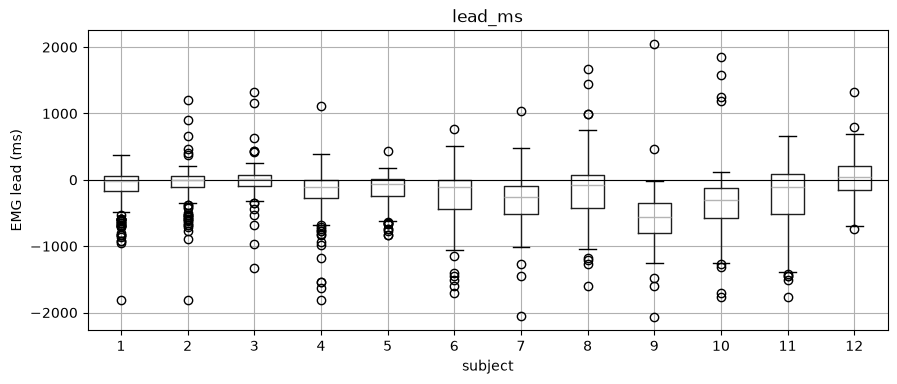

In [1]:
import sys, glob, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.append(r"D:\emg-project\src")
from emgproc import load, clean, onset_leads

rows = []
for path in sorted(glob.glob(r"D:\emg-project\data\raw\DB8\S*_E1_A*.mat")):
    name = os.path.basename(path)[:-4]                      # e.g. S3_E1_A2
    subj = int(name.split("_")[0][1:]); sess = int(name.split("_A")[1])
    emg, glove, rs, rr = load(path)
    for mov, rep, L in onset_leads(clean(emg), glove, rs, rr):
        rows.append(dict(subject=subj, session=sess, movement=mov, rep=rep, lead_ms=L))
    print(name, "done")

df = pd.DataFrame(rows)
df.to_csv(r"D:\emg-project\results\onset_leads.csv", index=False)

# 1. One row per subject
print(df.groupby("subject").lead_ms.agg(
    n="count", median="median",
    q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
    emg_first_pct=lambda s: round((s > 0).mean() * 100)))

# 2. Median lead for every subject x movement (finds patterns like movement 8)
print(df.pivot_table(values="lead_ms", index="subject", columns="movement", aggfunc="median").round())

# 3. Spread per subject
df.boxplot(column="lead_ms", by="subject", figsize=(10, 4))
plt.axhline(0, color="k", lw=0.8); plt.ylabel("EMG lead (ms)"); plt.suptitle(""); plt.show()